Enter 2-bit input xy (00, 01, 10, 11):  11


Bell state: |Psi-> = (|01> - |10>)/sqrt(2)

Amplitudes (|q0 q1>):
|01> : +0.7071
|10> : -0.7071

Measurement counts (c1 c0): {'10': 521, '01': 503}
The two qubits ALWAYS give OPPOSITE results.


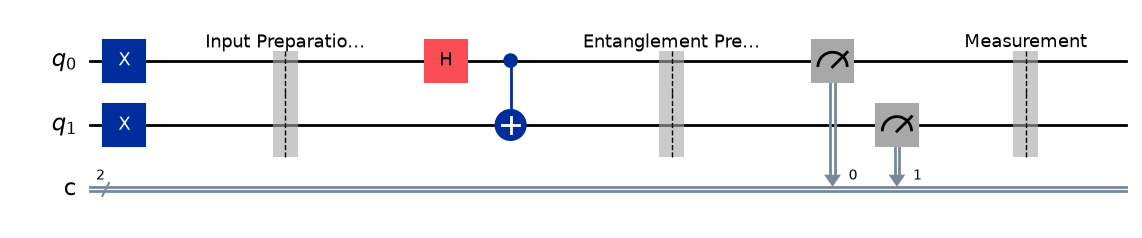

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
import numpy as np

# 1. User input: the two input bits x y select the Bell state
bits = input("Enter 2-bit input xy (00, 01, 10, 11): ")

if bits not in ["00", "01", "10", "11"]:
    raise ValueError("Enter a valid 2-bit input.")

x = int(bits[0])
y = int(bits[1])

bell_names = {
    "00": "|Phi+> = (|00> + |11>)/sqrt(2)",
    "01": "|Psi+> = (|01> + |10>)/sqrt(2)",
    "10": "|Phi-> = (|00> - |11>)/sqrt(2)",
    "11": "|Psi-> = (|01> - |10>)/sqrt(2)",
}

# 2. Create circuit
q = QuantumRegister(2, 'q')
c = ClassicalRegister(2, 'c')
qc = QuantumCircuit(q, c)

# 3. Prepare input |x y>
if x == 1:
    qc.x(q[0])
if y == 1:
    qc.x(q[1])

qc.barrier(label="Input Preparation")

# 4. Entangle: H on q[0], then CNOT q[0] -> q[1]
qc.h(q[0])
qc.cx(q[0], q[1])
qc.barrier(label="Entanglement Preparation")

# 5. Statevector of the Bell state
sv = Statevector(qc)

print("Bell state:", bell_names[bits])
print("\nAmplitudes (|q0 q1>):")

for q0 in range(2):
    for q1 in range(2):
        amplitude = sv.data[q0 + 2 * q1]
        if abs(amplitude) > 1e-8:
            print(f"|{q0}{q1}> : {amplitude.real:+.4f}")

# 6. Measurement
qc.measure(q[0], c[0])
qc.measure(q[1], c[1])
qc.barrier(label="Measurement")

# 7. Run circuit
result = AerSimulator().run(qc, shots=1024).result()
counts = result.get_counts()

print("\nMeasurement counts (c1 c0):", counts)

# 8. Correlation between the two qubits
same = sum(n for key, n in counts.items() if key[0] == key[1])

if same == 1024:
    print("The two qubits ALWAYS give the SAME result.")
elif same == 0:
    print("The two qubits ALWAYS give OPPOSITE results.")
else:
    print("Results are not perfectly correlated.")

# 9. Draw circuit
qc.draw(output='mpl', fold=-1, scale=1.0)

In [2]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("0_4_BellStates.png", dpi=300, bbox_inches="tight")